# Recency sample weights (not built)

**The question:** should the linear model and the hybrid weight recent training years more?

**Why it might:** the input–speed relationships change with the solar-cycle phase (Collin et al.
2025), and adding the old years didn't help at solar maximum (`docs/evaluation.md`).

**The weights** (`training.recency_weights`): each training run gets 0.5^(age / half-life), age =
years from the run to the end of the training data (the fold start), on top of the TIMSE
weights, normalised to mean 1 (`run_weights` in `LinearModel.fit` / `XGBoostModel.fit`).
Half-lives: ∞ (the shipped model), 8, 4, 2, 1 years.

**Setup** (`python -m training.recency_weights`, about 6 min):
- Six yearly walk-forward folds (2019-10 → 2025-10). Per fold, the linear model (shipped config,
  data fixes and cap) and the hybrid's trees on top are refitted on the data before the fold,
  both with the same half-life.
- "hybrid trees only": only the trees are weighted, on the unweighted linear model.
- Score: per-run mean TIMSE / persistence; summary: the geometric mean over folds.
- The eval year is not used.

1. Fold scores
2. Change by fold
3. Does the fold's cycle phase explain it?
4. Findings

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import recency_weights as rw

df = pd.read_csv(rw.EXPERIMENTS / "recency_weights.csv").set_index("fold")
H = [rw.label(h) for h in rw.HALF_LIVES]

## 1. Fold scores (lower is better)

In [2]:
def geo(c):
    return float(np.exp(np.log(df[c]).mean()))


rows = {}
for h in H:
    r = {}
    for m, ref in (("linear", "linear"), ("hybrid", "hybrid"), ("hybrid trees only", "hybrid")):
        c = f"{m} h={h}"
        if c in df:
            r[m] = geo(c)
            r[f"{m} vs ∞"] = geo(c) / geo(f"{ref} h=inf") - 1
            r[f"{m} folds won"] = int((df[c] < df[f"{ref} h=inf"]).sum())
    r["effective years (mean)"] = df[f"effective years h={h}"].mean()
    rows[h] = r
summary = pd.DataFrame(rows)
summary.columns.name = "half-life (years)"
with pd.option_context("display.float_format", "{:.4f}".format):
    display(summary)
    display(df[[c for c in df.columns if c.startswith(("linear", "hybrid"))]].T)

half-life (years),inf,8,4,2,1
linear,0.4375,0.4388,0.4404,0.4443,0.4531
linear vs ∞,0.0000,0.0028,0.0064,0.0155,0.0356
linear folds won,0.0000,3.0000,3.0000,3.0000,2.0000
hybrid,0.4253,0.4276,0.4299,0.4355,0.4485
hybrid vs ∞,0.0000,0.0053,0.0107,0.0240,0.0544
hybrid folds won,0.0000,2.0000,1.0000,2.0000,2.0000
effective years (mean),5.4990,5.3695,5.0290,4.1110,2.6666
hybrid trees only,NaN,0.4280,0.4300,0.4310,0.4391
hybrid trees only vs ∞,NaN,0.0065,0.0111,0.0135,0.0325
hybrid trees only folds won,NaN,1.0000,1.0000,2.0000,1.0000


fold,2019-10,2020-10,2021-10,2022-10,2023-10,2024-10
linear h=inf,0.4282,0.3678,0.4981,0.4626,0.5554,0.3481
hybrid h=inf,0.3960,0.3604,0.4900,0.4573,0.5488,0.3371
linear h=8,0.4252,0.3672,0.5024,0.4631,0.5542,0.3545
hybrid h=8,0.3983,0.3598,0.4990,0.4602,0.5447,0.3409
hybrid trees only h=8,0.3991,0.3618,0.5030,0.4599,0.5461,0.3372
linear h=4,0.4225,0.3668,0.5073,0.4635,0.5530,0.3619
hybrid h=4,0.3969,0.3650,0.5026,0.4616,0.5430,0.3458
hybrid trees only h=4,0.3948,0.3646,0.5062,0.4610,0.5513,0.3416
linear h=2,0.4178,0.3667,0.5186,0.4638,0.5516,0.3785
hybrid h=2,0.3895,0.3705,0.5184,0.4701,0.5382,0.3604


## 2. Change against no recency weighting, by fold

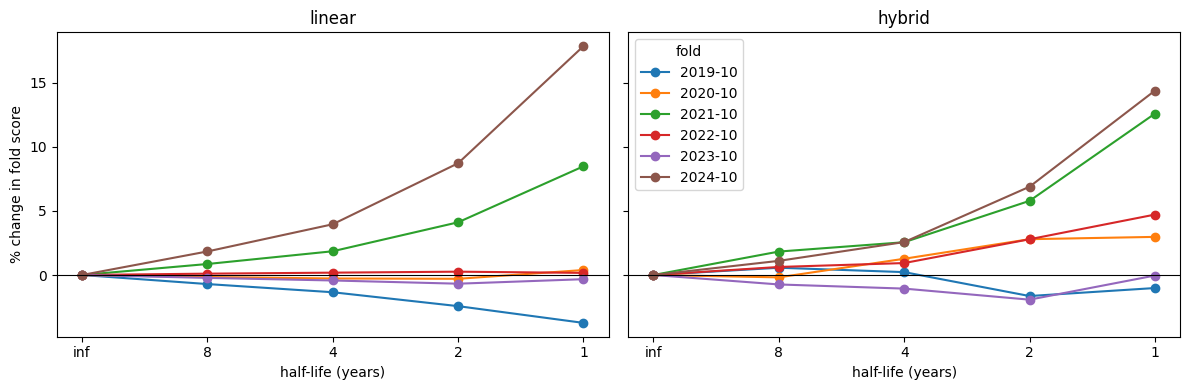

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, m in zip(axes, ("linear", "hybrid"), strict=True):
    for fold in df.index:
        ax.plot(H, 100 * (df.loc[fold, [f"{m} h={h}" for h in H]].to_numpy()
                          / df.loc[fold, f"{m} h=inf"] - 1), "o-", label=fold)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(m)
    ax.set_xlabel("half-life (years)")
axes[0].set_ylabel("% change in fold score")
axes[1].legend(title="fold")
plt.tight_layout()

## 3. Does the fold's cycle phase explain it?

Recency weighting says "the near future looks like the recent past". That should hold while the
cycle phase continues, and fail when it turns. Below: the mean F10.7 (solar activity) of each fold
year and of the two training years just before it, against the change at half-life 2 years.

In [4]:
from training import compare_history as ch

data = ch.Data()
f107 = data.table["f107_mean_24h"]
rows = []
for start, end in rw.YEARLY:
    fold_mean = f107[(f107.index >= start) & (f107.index < end)].mean()
    recent = f107[(f107.index >= start - 2 * rw.YEAR) & (f107.index < start)].mean()
    rows.append({"fold": f"{start:%Y-%m}", "F10.7 fold year": fold_mean,
                 "F10.7 last 2 training years": recent,
                 "fold / recent": fold_mean / recent,
                 "linear h=2 change": df.loc[f"{start:%Y-%m}", "linear h=2"]
                 / df.loc[f"{start:%Y-%m}", "linear h=inf"] - 1,
                 "hybrid h=2 change": df.loc[f"{start:%Y-%m}", "hybrid h=2"]
                 / df.loc[f"{start:%Y-%m}", "hybrid h=inf"] - 1})
phase = pd.DataFrame(rows).set_index("fold")
display(phase.round(3))

,F10.7 fold year,F10.7 last 2 training years,fold / recent,linear h=2 change,hybrid h=2 change
fold,,,,,
2019-10,70.430000,70.070000,1.005,-0.024,-0.016
2020-10,79.891998,70.000999,1.141,-0.003,0.028
2021-10,117.441002,75.161003,1.563,0.041,0.058
2022-10,156.552002,98.651001,1.587,0.003,0.028
2023-10,181.149994,136.953995,1.323,-0.007,-0.019
2024-10,165.628998,168.906006,0.981,0.087,0.069


## 4. Findings

- **Not built: recency weighting is worse at every half-life.** Over the six folds, an 8-year half-life costs 0.3% (linear) and 0.5% (hybrid); 1 year costs 3.6% / 5.4%. No half-life wins more than 3 of 6 folds.
- **Weighting only the trees doesn't help either** (+0.7% to +3.3%), so the loss isn't only the linear anchor's.
- **The folds disagree.** The 2019 fold gains steadily (linear −3.7% at a 1-year half-life), and the 2023 fold a little. The 2021 and 2024 folds lose heavily (up to +8.5% and +18%).
- **Activity level explains it only partly.** In 2019 the fold year's mean F10.7 matches the two years before it (ratio 1.00) and recency helps; in 2021 activity jumped (1.56) and it hurts. But 2024 also matches its recent years (0.98) and loses the most. A cycle-phase similarity weight based on the F10.7 level would not have rescued that fold.
- **The likely reason is data, not drift.** Halving the effective history (5.5 → 2.7 years at a 1-year half-life) costs more than any change in the relationships gains. It matches the history comparison fold by fold (docs/evaluation.md): the 2024 fold gained 12% from adding the 2016–2020 years and is the one recency hurts most; on the 2023 fold the old years didn't help, and recency gains slightly there.
- **Decision:** not built. The `run_weights` hook stays in `LinearModel.fit` and `XGBoostModel.fit` (default: no weighting); `training.recency_weights` and this notebook are the record (`docs/recency_weights.md`).